# LSTM exploration

This notebook includes the best-performing models for LSTM models, both global and individual, and non-recurrent models. Some best-performing municipalities repeat themselves, so I only plot them once.

In [1]:
import pandas as pd
import sys
from pathlib import Path
import matplotlib.pyplot as plt
import joblib
import numpy as np
from matplotlib.lines import Line2D
import matplotlib.transforms as transforms

sys.path.append('../')

from model_recurrent import Model

In [2]:
df = pd.read_csv("../full_data.csv")

# Best-performing

For non-recurrent models, the best are: 117, 101, 201, 110.

In [3]:
confints = pd.read_csv(f"../data/metrics/nrmse_lstm_confint.csv")
confints.head()

,canton,train_point_ind,train_lower_ind,train_upper_ind,train_point_global,train_lower_global,train_upper_global,test_point_ind,test_lower_ind,test_upper_ind,test_point_global,test_lower_global,test_upper_global
0,101,0.364140,0.289012,0.476068,0.611888,0.521367,0.708155,0.363290,0.306951,0.404951,0.506249,0.437141,0.558422
1,102,1.061527,0.821540,1.261453,0.912163,0.605214,1.154129,1.217134,1.097229,1.341808,1.128394,0.965995,1.294708
2,103,0.331629,0.256005,0.414361,0.590405,0.486385,0.674933,0.906881,0.606200,1.029905,0.744337,0.503072,0.825934
3,104,1.425756,1.054345,1.729534,1.315338,0.904635,1.627707,1.568818,1.327075,1.758772,1.573887,1.282681,1.770329
4,105,0.924526,0.576664,1.151055,0.948123,0.617297,1.170258,2.262762,1.008579,2.468795,2.254943,0.370043,2.423143


## Global

In [4]:
sorted_confint_global = confints.sort_values(by = "test_point_global", ascending = True)
display(sorted_confint_global.head(4))
display(sorted_confint_global.tail(4))

,canton,train_point_ind,train_lower_ind,train_upper_ind,train_point_global,train_lower_global,train_upper_global,test_point_ind,test_lower_ind,test_upper_ind,test_point_global,test_lower_global,test_upper_global
16,117,3.808581,1.030647,4.432442,3.743615,1.441074,4.389984,0.363001,0.284959,0.422484,0.102618,0.077416,0.119000
0,101,0.364140,0.289012,0.476068,0.611888,0.521367,0.708155,0.363290,0.306951,0.404951,0.506249,0.437141,0.558422
20,201,0.636366,0.539425,0.747681,0.583365,0.530762,0.644419,0.490483,0.380075,0.575095,0.627000,0.499658,0.739962
65,601,0.830225,0.739537,0.939803,0.653776,0.571426,0.741106,0.898994,0.792499,1.031763,0.675486,0.498498,0.880491


,canton,train_point_ind,train_lower_ind,train_upper_ind,train_point_global,train_lower_global,train_upper_global,test_point_ind,test_lower_ind,test_upper_ind,test_point_global,test_lower_global,test_upper_global
41,306,1.984974,0.390741,2.700182,1.974673,0.530231,2.727920,2.639003,0.409980,3.329890,2.639142,1.258417,3.335384
30,211,1.114189,0.109745,1.642726,1.122045,0.138611,1.650900,2.932111,0.045943,2.947049,2.927348,0.084179,2.942330
23,204,2.983185,1.795284,3.808892,2.818299,1.850434,3.553463,3.069015,2.226303,3.951727,3.100237,2.207348,4.209190
15,116,3.269016,2.344266,4.043528,2.195519,1.642540,3.007023,3.644984,1.170698,3.669634,3.605874,0.339951,3.608721


## Individual

In [5]:
sorted_confint_ind = confints.sort_values(by = "test_point_ind", ascending = True)
display(sorted_confint_ind.head(4))
display(sorted_confint_ind.tail(4))

,canton,train_point_ind,train_lower_ind,train_upper_ind,train_point_global,train_lower_global,train_upper_global,test_point_ind,test_lower_ind,test_upper_ind,test_point_global,test_lower_global,test_upper_global
16,117,3.808581,1.030647,4.432442,3.743615,1.441074,4.389984,0.363001,0.284959,0.422484,0.102618,0.077416,0.119000
0,101,0.364140,0.289012,0.476068,0.611888,0.521367,0.708155,0.363290,0.306951,0.404951,0.506249,0.437141,0.558422
20,201,0.636366,0.539425,0.747681,0.583365,0.530762,0.644419,0.490483,0.380075,0.575095,0.627000,0.499658,0.739962
48,405,0.889232,0.537668,1.137648,0.863542,0.501973,1.118943,0.821138,0.008410,1.109346,0.815616,0.103319,1.106745


,canton,train_point_ind,train_lower_ind,train_upper_ind,train_point_global,train_lower_global,train_upper_global,test_point_ind,test_lower_ind,test_upper_ind,test_point_global,test_lower_global,test_upper_global
81,706,0.883884,0.756864,1.020677,0.720671,0.597889,0.843765,2.642020,1.813065,4.134847,1.330397,0.861709,1.684452
30,211,1.114189,0.109745,1.642726,1.122045,0.138611,1.650900,2.932111,0.045943,2.947049,2.927348,0.084179,2.942330
23,204,2.983185,1.795284,3.808892,2.818299,1.850434,3.553463,3.069015,2.226303,3.951727,3.100237,2.207348,4.209190
15,116,3.269016,2.344266,4.043528,2.195519,1.642540,3.007023,3.644984,1.170698,3.669634,3.605874,0.339951,3.608721


# Global models

c:\Users\nan\OneDrive\Documentos\ucr\practica profesiona\dengue-recurrent-cr\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


c:\Users\nan\OneDrive\Documentos\ucr\practica profesiona\dengue-recurrent-cr\.venv\Lib\site-packages\keras\src\models\functional.py:259: UserWarning: The structure of `inputs` doesn't match the expected structure.
Expected: input_layer
Received: inputs=['Tensor(shape=(500, 12, 29))']
  warnings.warn(msg)
c:\Users\nan\OneDrive\Documentos\ucr\practica profesiona\dengue-recurrent-cr\.venv\Lib\site-packages\keras\src\models\functional.py:259: UserWarning: The structure of `inputs` doesn't match the expected structure.
Expected: input_layer
Received: inputs=['Tensor(shape=(50, 12, 29))']
  warnings.warn(msg)


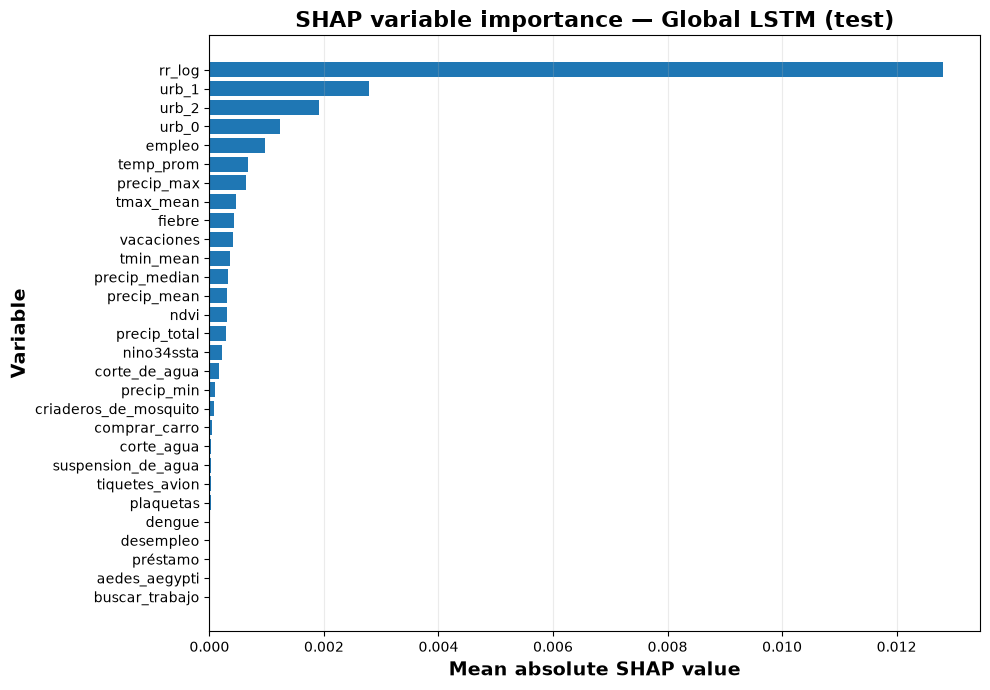

In [6]:
model0 = Model(df, "full")

shap_values_global, importance_global, fig, ax = (
    model0.shap_lstm_full(
        split="test"
    )
)

# Best-performing

BlockBootstrap ACI LSTM execution time: 582.35 seconds


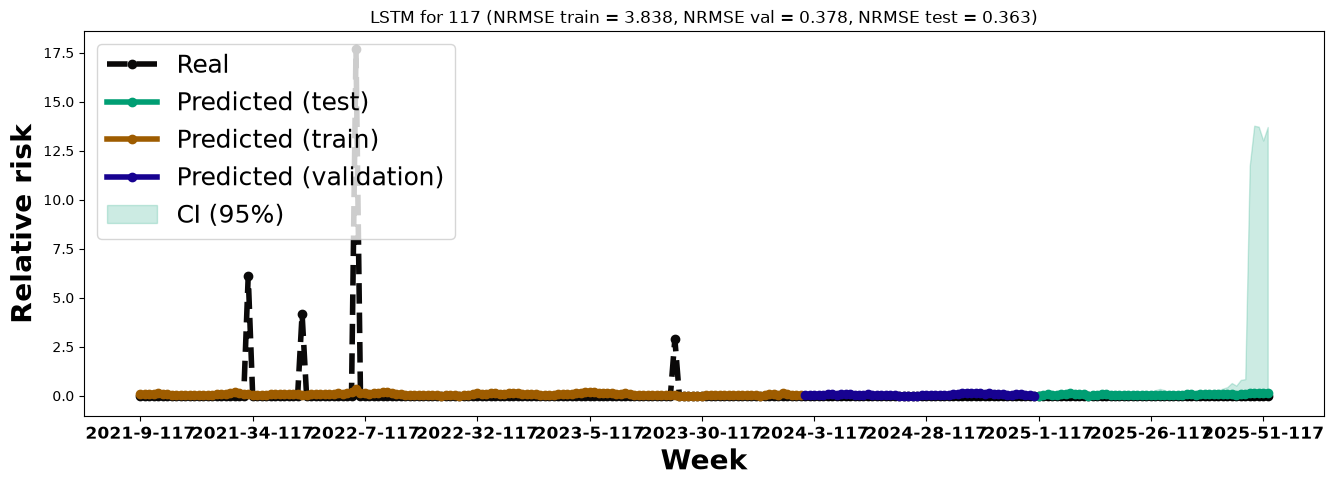

c:\Users\nan\OneDrive\Documentos\ucr\practica profesiona\dengue-recurrent-cr\.venv\Lib\site-packages\sklearn\utils\validation.py:1368: DataConversionWarning: A column-vector y was passed when a 1d array was expected. Please change the shape of y to (n_samples, ), for example using ravel().
  y = column_or_1d(y, warn=True)


BlockBootstrap ACI global LSTM execution time: 531.76 seconds


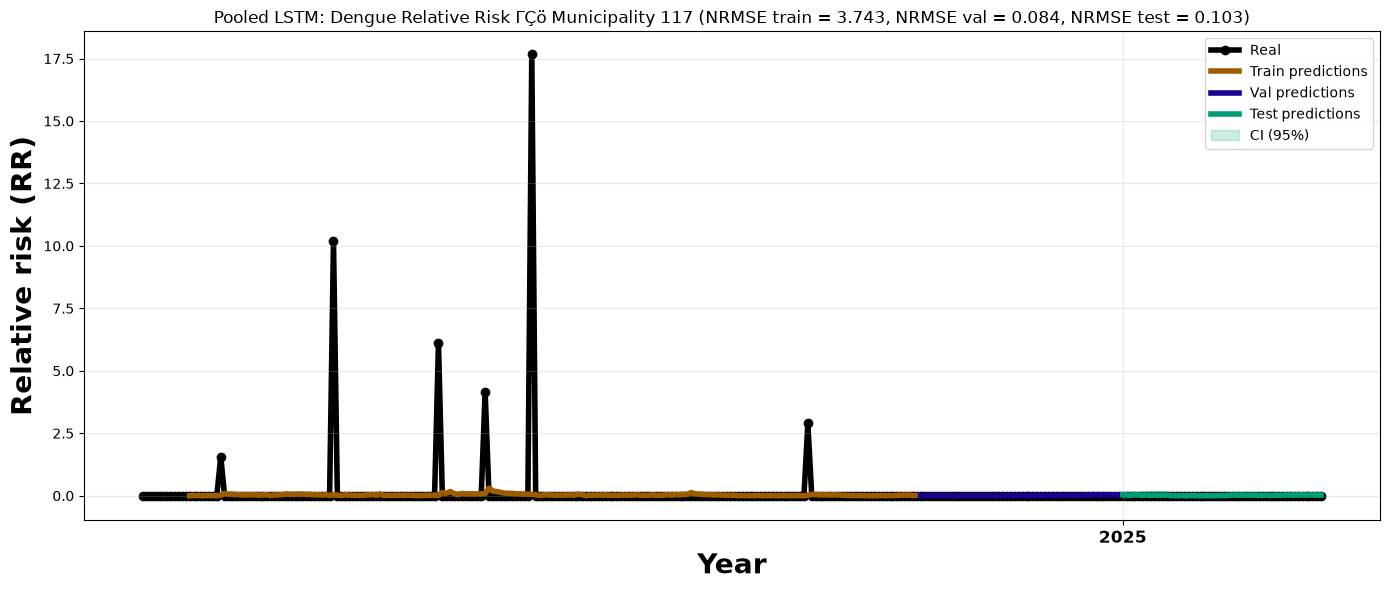

c:\Users\nan\OneDrive\Documentos\ucr\practica profesiona\dengue-recurrent-cr\.venv\Lib\site-packages\keras\src\models\functional.py:259: UserWarning: The structure of `inputs` doesn't match the expected structure.
Expected: input_layer
Received: inputs=['Tensor(shape=(52, 52, 27))']
  warnings.warn(msg)
c:\Users\nan\OneDrive\Documentos\ucr\practica profesiona\dengue-recurrent-cr\.venv\Lib\site-packages\keras\src\models\functional.py:259: UserWarning: The structure of `inputs` doesn't match the expected structure.
Expected: input_layer
Received: inputs=['Tensor(shape=(50, 52, 27))']
  warnings.warn(msg)


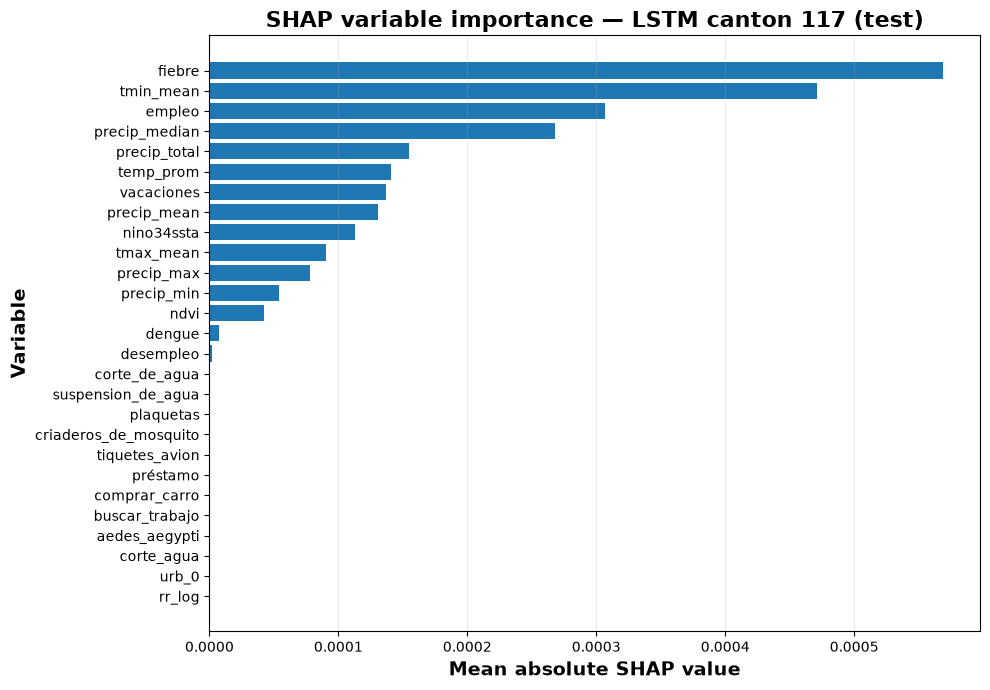

In [7]:
model0 = Model(df, "117")

model0.lstm_forecast_plot()
model0.plot_forecast_lstm_full()

shap_values0, importance0, fig, ax = (
    model0.shap_lstm_individual(
        split="test"
    )
)

BlockBootstrap ACI LSTM execution time: 899.21 seconds


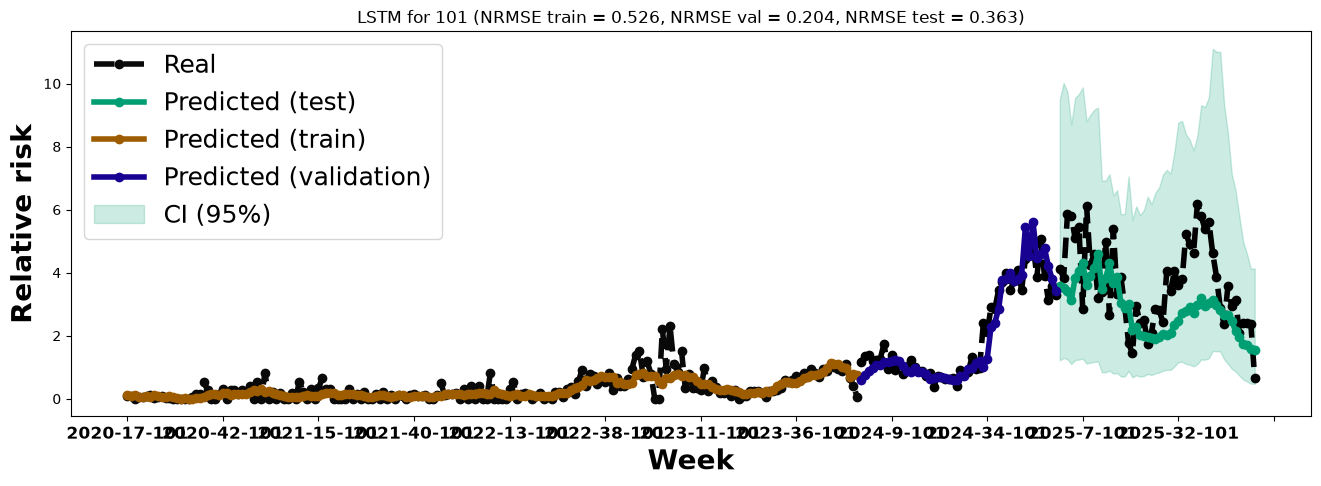

c:\Users\nan\OneDrive\Documentos\ucr\practica profesiona\dengue-recurrent-cr\.venv\Lib\site-packages\sklearn\utils\validation.py:1368: DataConversionWarning: A column-vector y was passed when a 1d array was expected. Please change the shape of y to (n_samples, ), for example using ravel().
  y = column_or_1d(y, warn=True)


BlockBootstrap ACI global LSTM execution time: 368.44 seconds


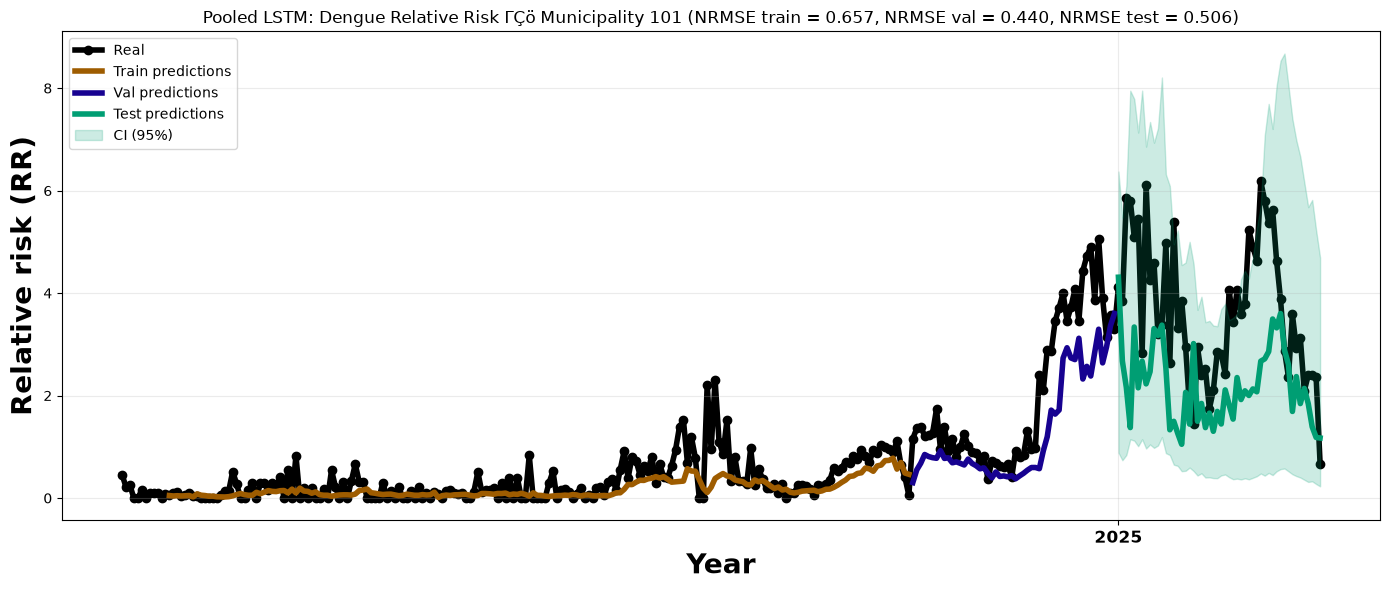

c:\Users\nan\OneDrive\Documentos\ucr\practica profesiona\dengue-recurrent-cr\.venv\Lib\site-packages\keras\src\models\functional.py:259: UserWarning: The structure of `inputs` doesn't match the expected structure.
Expected: input_layer
Received: inputs=['Tensor(shape=(52, 8, 27))']
  warnings.warn(msg)
c:\Users\nan\OneDrive\Documentos\ucr\practica profesiona\dengue-recurrent-cr\.venv\Lib\site-packages\keras\src\models\functional.py:259: UserWarning: The structure of `inputs` doesn't match the expected structure.
Expected: input_layer
Received: inputs=['Tensor(shape=(50, 8, 27))']
  warnings.warn(msg)


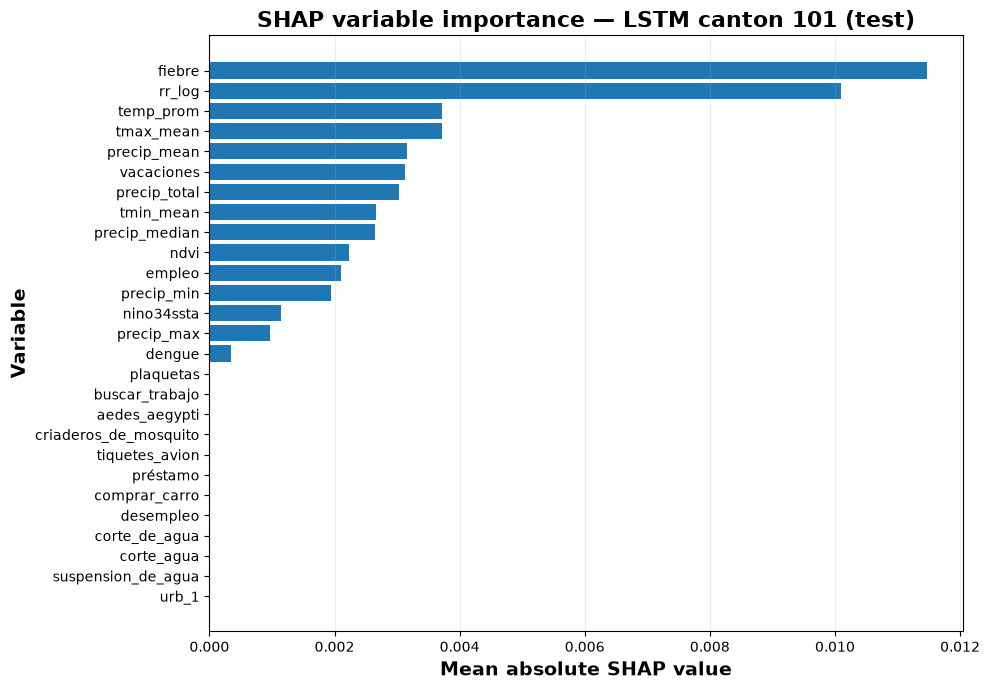

In [8]:
model0 = Model(df, "101")

model0.lstm_forecast_plot()
model0.plot_forecast_lstm_full()

shap_values0, importance0, fig, ax = (
    model0.shap_lstm_individual(
        split="test"
    )
)

BlockBootstrap ACI LSTM execution time: 359.14 seconds


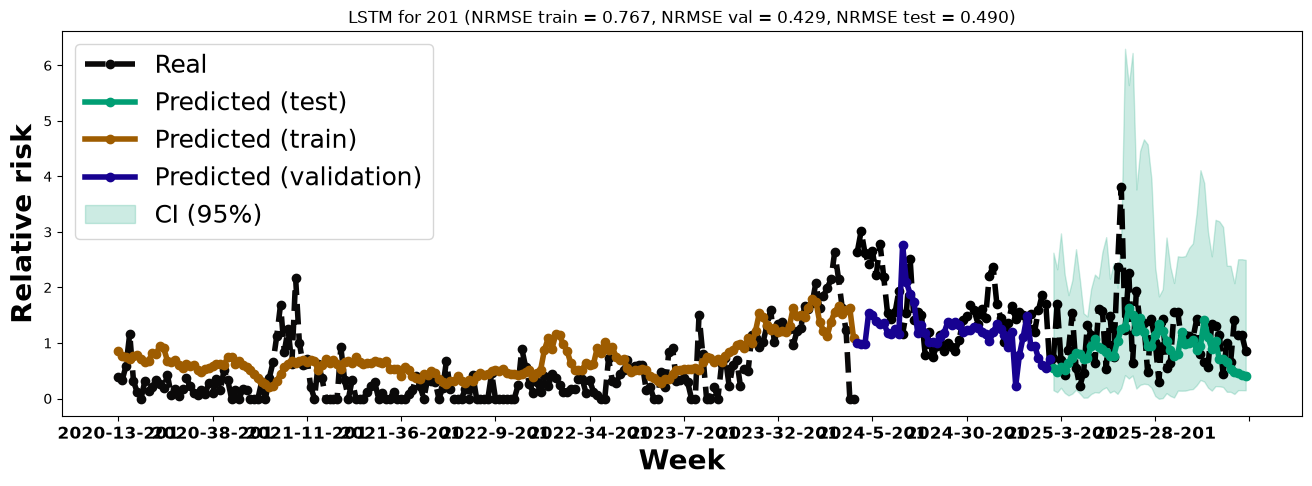

c:\Users\nan\OneDrive\Documentos\ucr\practica profesiona\dengue-recurrent-cr\.venv\Lib\site-packages\sklearn\utils\validation.py:1368: DataConversionWarning: A column-vector y was passed when a 1d array was expected. Please change the shape of y to (n_samples, ), for example using ravel().
  y = column_or_1d(y, warn=True)


BlockBootstrap ACI global LSTM execution time: 380.04 seconds


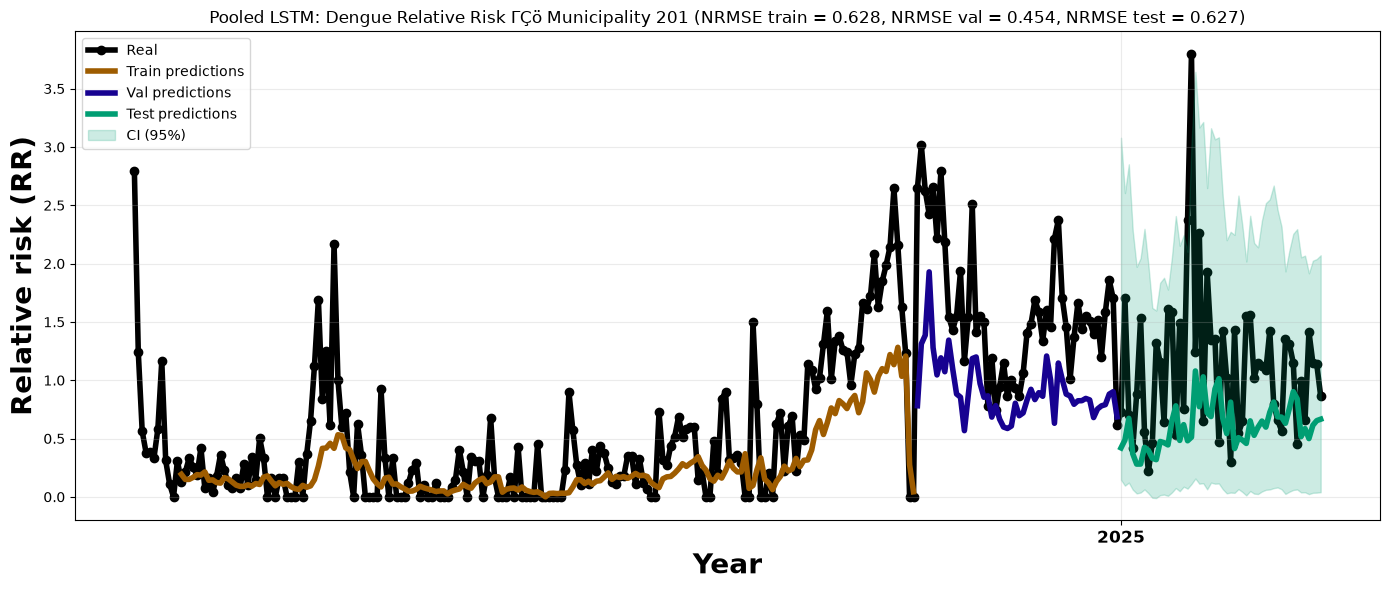

c:\Users\nan\OneDrive\Documentos\ucr\practica profesiona\dengue-recurrent-cr\.venv\Lib\site-packages\keras\src\models\functional.py:259: UserWarning: The structure of `inputs` doesn't match the expected structure.
Expected: input_layer
Received: inputs=['Tensor(shape=(52, 4, 27))']
  warnings.warn(msg)
c:\Users\nan\OneDrive\Documentos\ucr\practica profesiona\dengue-recurrent-cr\.venv\Lib\site-packages\keras\src\models\functional.py:259: UserWarning: The structure of `inputs` doesn't match the expected structure.
Expected: input_layer
Received: inputs=['Tensor(shape=(50, 4, 27))']
  warnings.warn(msg)


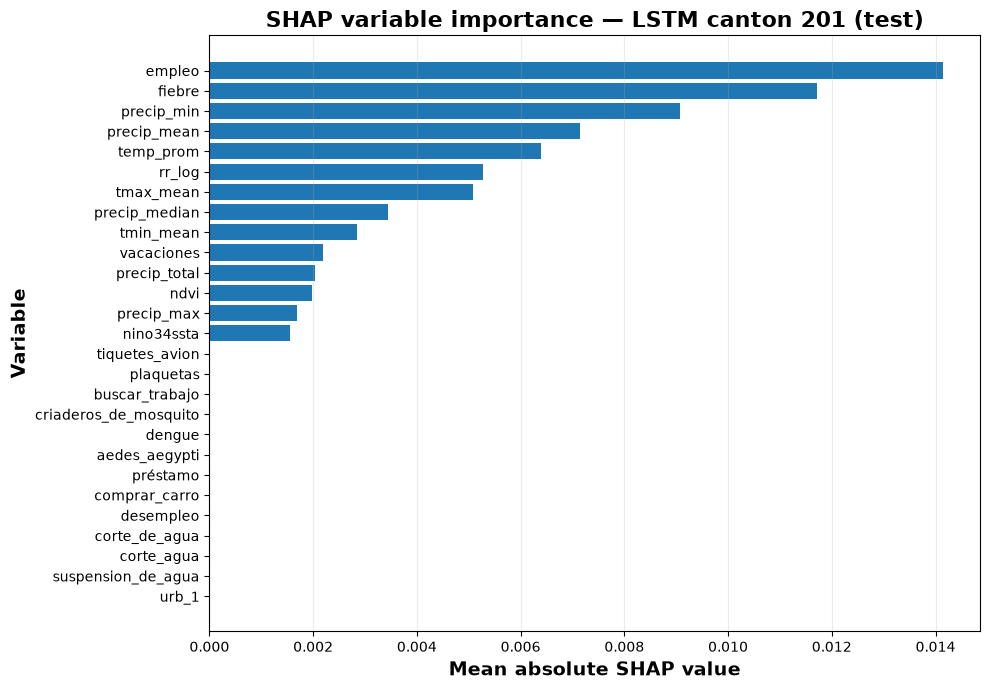

In [9]:
model0 = Model(df, "201")

model0.lstm_forecast_plot()
model0.plot_forecast_lstm_full()

shap_values0, importance0, fig, ax = (
    model0.shap_lstm_individual(
        split="test"
    )
)

BlockBootstrap ACI LSTM execution time: 418.18 seconds


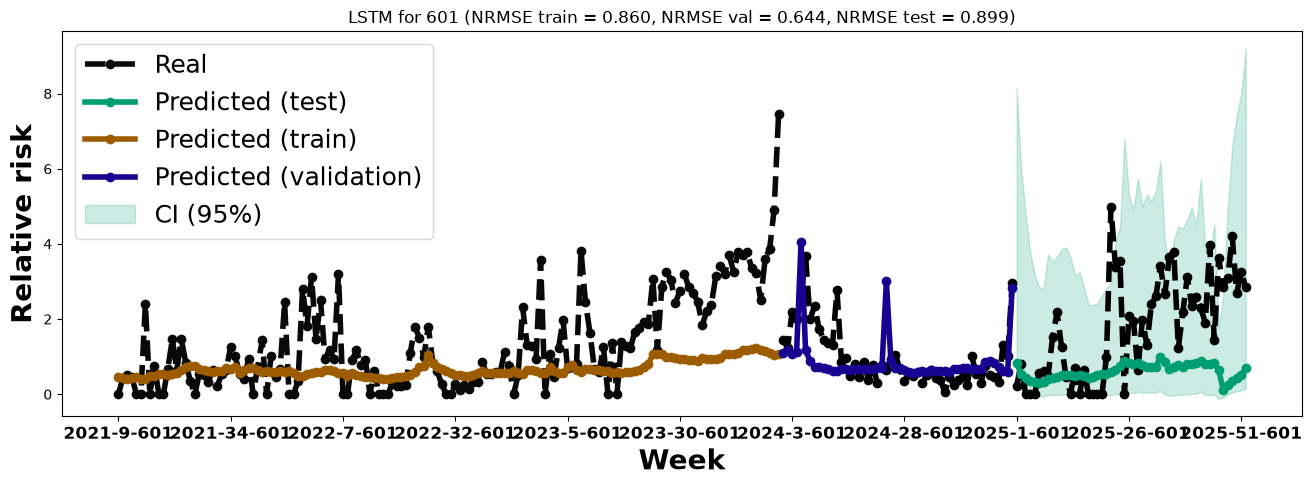

c:\Users\nan\OneDrive\Documentos\ucr\practica profesiona\dengue-recurrent-cr\.venv\Lib\site-packages\sklearn\utils\validation.py:1368: DataConversionWarning: A column-vector y was passed when a 1d array was expected. Please change the shape of y to (n_samples, ), for example using ravel().
  y = column_or_1d(y, warn=True)


BlockBootstrap ACI global LSTM execution time: 376.32 seconds


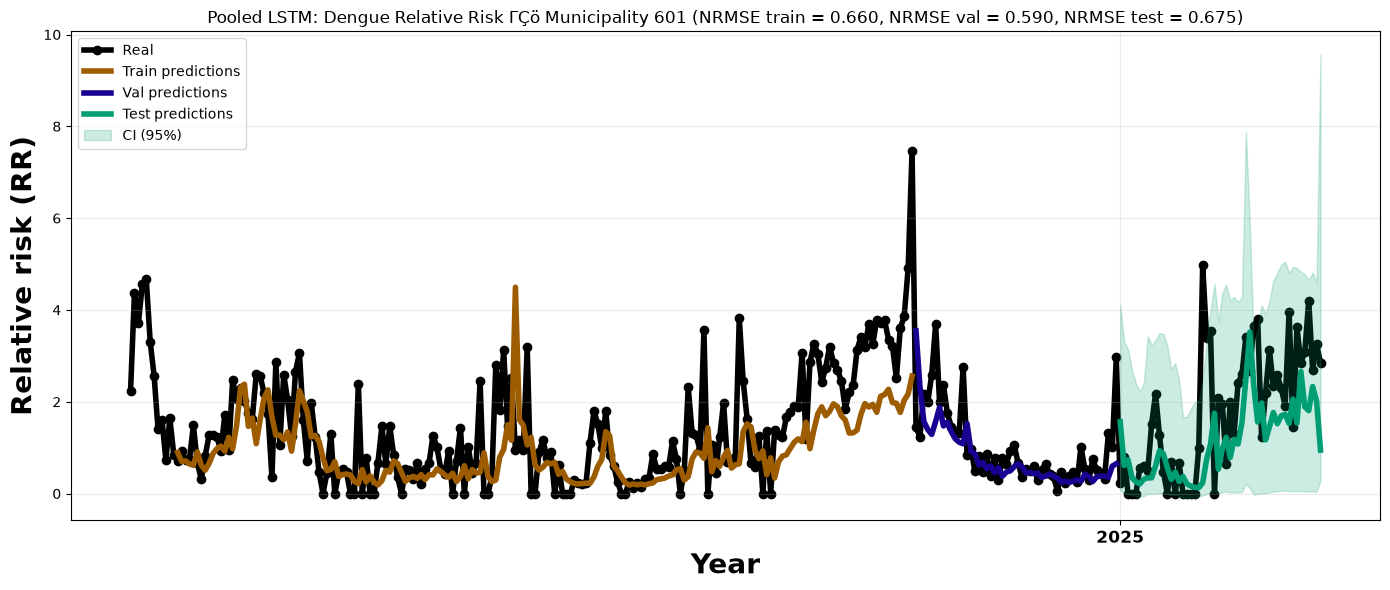

c:\Users\nan\OneDrive\Documentos\ucr\practica profesiona\dengue-recurrent-cr\.venv\Lib\site-packages\keras\src\models\functional.py:259: UserWarning: The structure of `inputs` doesn't match the expected structure.
Expected: input_layer
Received: inputs=['Tensor(shape=(52, 52, 27))']
  warnings.warn(msg)
c:\Users\nan\OneDrive\Documentos\ucr\practica profesiona\dengue-recurrent-cr\.venv\Lib\site-packages\keras\src\models\functional.py:259: UserWarning: The structure of `inputs` doesn't match the expected structure.
Expected: input_layer
Received: inputs=['Tensor(shape=(50, 52, 27))']
  warnings.warn(msg)


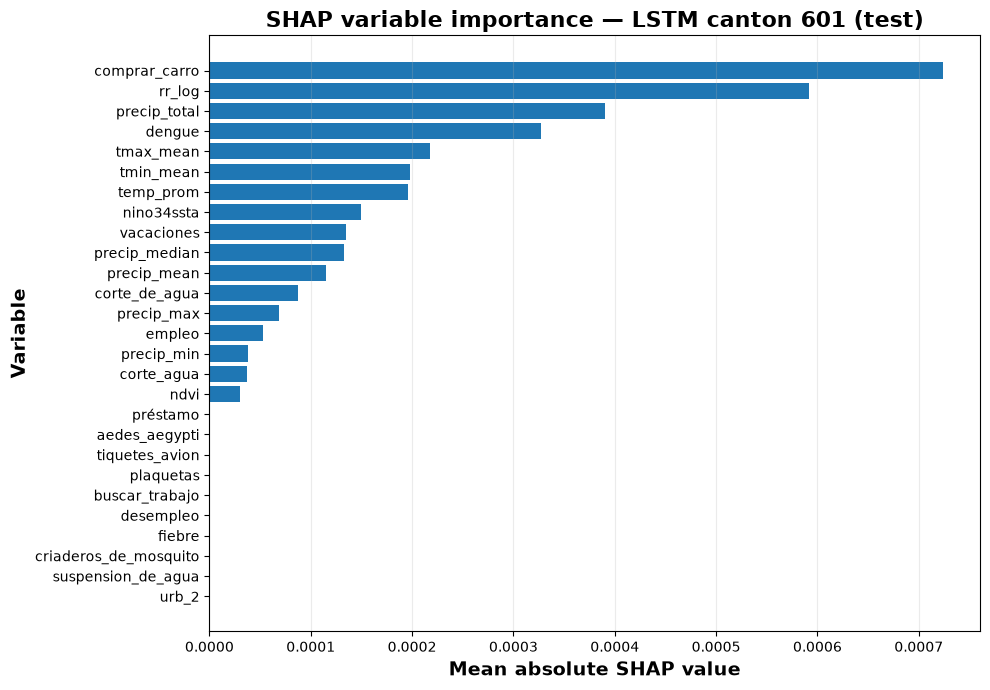

In [10]:
model0 = Model(df, "601")

model0.lstm_forecast_plot()
model0.plot_forecast_lstm_full()

shap_values0, importance0, fig, ax = (
    model0.shap_lstm_individual(
        split="test"
    )
)

BlockBootstrap ACI LSTM execution time: 491.57 seconds


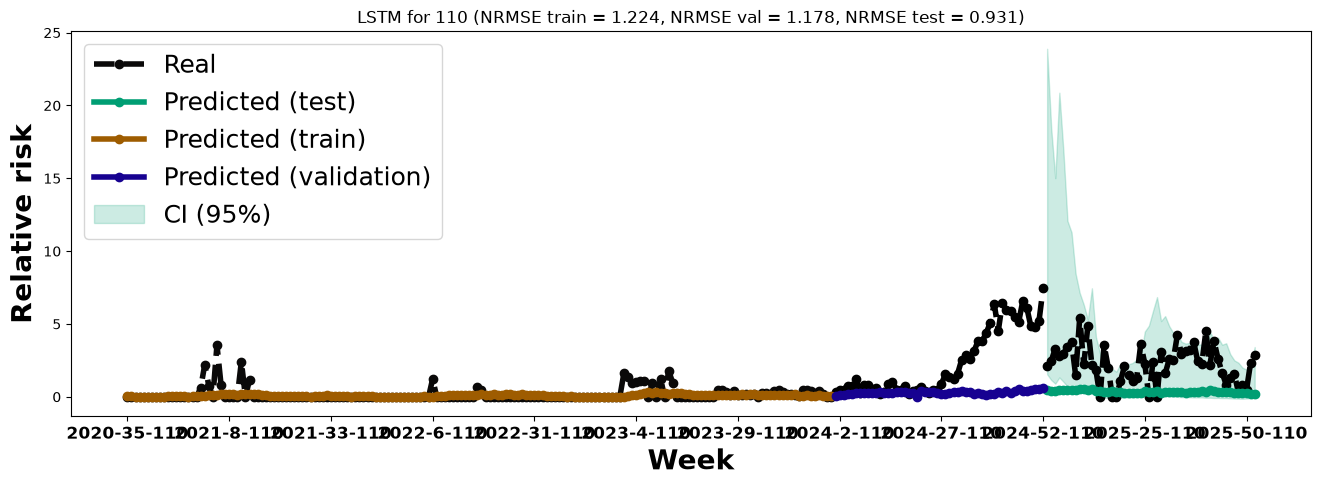

c:\Users\nan\OneDrive\Documentos\ucr\practica profesiona\dengue-recurrent-cr\.venv\Lib\site-packages\keras\src\models\functional.py:259: UserWarning: The structure of `inputs` doesn't match the expected structure.
Expected: input_layer
Received: inputs=['Tensor(shape=(52, 26, 27))']
  warnings.warn(msg)
c:\Users\nan\OneDrive\Documentos\ucr\practica profesiona\dengue-recurrent-cr\.venv\Lib\site-packages\keras\src\models\functional.py:259: UserWarning: The structure of `inputs` doesn't match the expected structure.
Expected: input_layer
Received: inputs=['Tensor(shape=(50, 26, 27))']
  warnings.warn(msg)


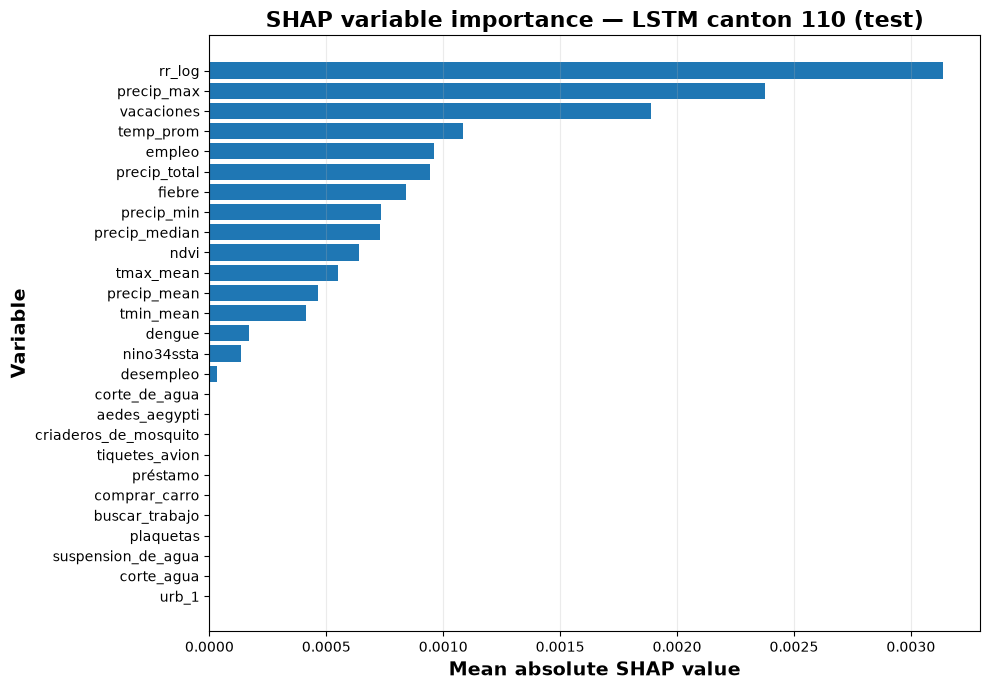

In [11]:
model0 = Model(df, "110")

model0.lstm_forecast_plot()

shap_values0, importance0, fig, ax = (
    model0.shap_lstm_individual(
        split="test"
    )
)

BlockBootstrap ACI LSTM execution time: 332.22 seconds


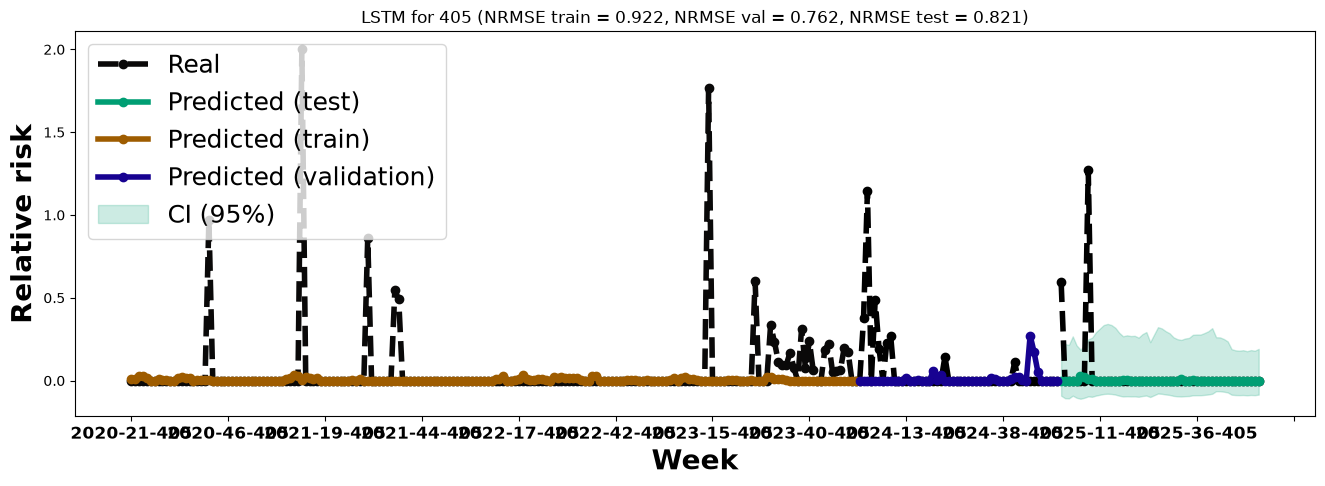

c:\Users\nan\OneDrive\Documentos\ucr\practica profesiona\dengue-recurrent-cr\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
c:\Users\nan\OneDrive\Documentos\ucr\practica profesiona\dengue-recurrent-cr\.venv\Lib\site-packages\keras\src\models\functional.py:259: UserWarning: The structure of `inputs` doesn't match the expected structure.
Expected: input_layer
Received: inputs=['Tensor(shape=(52, 12, 27))']
  warnings.warn(msg)
c:\Users\nan\OneDrive\Documentos\ucr\practica profesiona\dengue-recurrent-cr\.venv\Lib\site-packages\keras\src\models\functional.py:259: UserWarning: The structure of `inputs` doesn't match the expected structure.
Expected: input_layer
Received: inputs=['Tensor(shape=(50, 12, 27))']
  warnings.warn(msg)


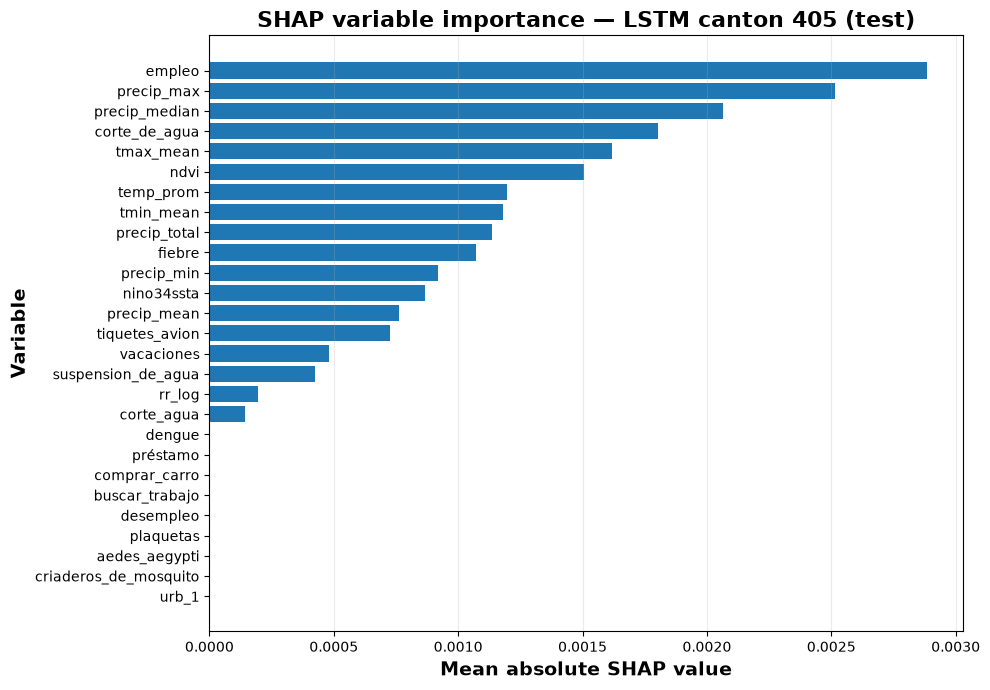

In [4]:
model0 = Model(df, "405")

model0.lstm_forecast_plot()

shap_values0, importance0, fig, ax = (
    model0.shap_lstm_individual(
        split="test"
    )
)